In [ ]:
stress_strain_practice.csv


In [3]:
# Import necessary libraries
import pandas as pd
from google.colab import files

# ---------------------------------------------------------
# Upload "stress_strain_practice.csv" to your Colab session
# ---------------------------------------------------------
uploaded = files.upload()

# 1. Load the CSV file and display the first 5 rows
df = pd.read_csv('stress_strain_practice.csv')
print("--- First 5 Rows of Dataset ---")
print(df.head())
print("\n")

# 2. Calculate Stress (MPa) = Force (N) / Area (mm^2)
# Note: 1 N/mm^2 is directly equal to 1 MPa
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']

# 3. Calculate Strain (%) = (Elongation / Original_Length) * 100
df['Strain_Percent'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100

print("--- Dataset with Calculated Stress & Strain (First 5 Rows) ---")
print(df[['Test_ID', 'Material', 'Stress_MPa', 'Strain_Percent']].head())
print("\n")

# 4. Group results by Material and show average Stress and Strain
avg_by_material = df.groupby('Material')[['Stress_MPa', 'Strain_Percent']].mean().reset_index()
print("--- Average Stress and Strain by Material ---")
print(avg_by_material)
print("\n")

# 5. Identify which material type is strongest (highest average stress)
strongest_row = avg_by_material.loc[avg_by_material['Stress_MPa'].idxmax()]
strongest_material = strongest_row['Material']
highest_avg_stress = strongest_row['Stress_MPa']

print(f"--- Strongest Material ---")
print(f"The strongest material is '{strongest_material}' with an average stress of {highest_avg_stress:.2f} MPa.\n")

# 6. Create a summary showing min, max, and average stress for each material
stress_summary = df.groupby('Material')['Stress_MPa'].agg(
    Min_Stress_MPa='min',
    Max_Stress_MPa='max',
    Avg_Stress_MPa='mean'
).reset_index()

print("--- Stress Summary (Min, Max, Average) by Material ---")
print(stress_summary)
print("\n")

# 7. Export results to new CSV files and download them in Google Colab
# Export the full dataset with the newly calculated Stress and Strain columns
output_detailed_file = 'stress_strain_results.csv'
df.to_csv(output_detailed_file, index=False)

# Export the material summary table as well
output_summary_file = 'material_stress_summary.csv'
stress_summary.to_csv(output_summary_file, index=False)

print(f"Exported detailed results to '{output_detailed_file}' and summary to '{output_summary_file}'.")

# Automatically trigger download to your computer from Google Colab
files.download(output_detailed_file)
files.download(output_summary_file)

Saving stress_strain_practice.csv to stress_strain_practice.csv
--- First 5 Rows of Dataset ---
  Test_ID  Material  Force_N  Cross_Section_Area_mm2  Elongation_mm  \
0    T001     Steel     1749                      27           0.51   
1    T002  Aluminum     2901                      20           0.45   
2    T003    Copper     2463                      19           0.76   
3    T004     Brass     2197                      33           0.50   
4    T005  Titanium     1312                      33           0.45   

   Original_Length_mm   Test_Date  
0                 100  2025-01-01  
1                 100  2025-01-02  
2                 100  2025-01-03  
3                 100  2025-01-04  
4                 100  2025-01-05  


--- Dataset with Calculated Stress & Strain (First 5 Rows) ---
  Test_ID  Material  Stress_MPa  Strain_Percent
0    T001     Steel   64.777778            0.51
1    T002  Aluminum  145.050000            0.45
2    T003    Copper  129.631579            0.76
3   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# Import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files

# ---------------------------------------------------------
# Optional: Uncomment the line below to upload your file in Colab
# ---------------------------------------------------------
# uploaded = files.upload()

# 1. Load the CSV file with error handling for missing file or missing values
try:
  df = pd.read_csv('stress_strain_practice.csv')
except FileNotFoundError:
  raise FileNotFoundError(
      "Could not find 'stress_strain_practice.csv'. Please upload it to your"
      ' Colab session first.'
  )

# Check for missing values in required numeric columns
required_cols = [
    'Force_N',
    'Cross_Section_Area_mm2',
    'Elongation_mm',
    'Original_Length_mm',
    'Material',
]
missing_before = df[required_cols].isnull().sum()
print('--- Missing Values Check (Before Cleaning) ---')
print(missing_before)
print('\n')

# Convert numeric columns safely (coercing invalid strings like 'N/A' or '-' into NaN)
numeric_cols = [
    'Force_N',
    'Cross_Section_Area_mm2',
    'Elongation_mm',
    'Original_Length_mm',
]
for col in numeric_cols:
  df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with missing values or zero/negative dimensions to prevent ZeroDivisionError
initial_rows = len(df)
df = df.dropna(subset=required_cols).copy()
df = df[
    (df['Cross_Section_Area_mm2'] > 0) & (df['Original_Length_mm'] > 0)
].copy()
dropped_rows = initial_rows - len(df)

if dropped_rows > 0:
  print(
      f'Warning: Removed {dropped_rows} invalid/incomplete row(s) with missing'
      ' values or zero dimensions.\n'
  )
else:
  print('All rows valid! No missing values or zero-division issues found.\n')

print('--- First 5 Valid Rows of Dataset ---')
print(df.head())
print('\n')

# 2. Calculate Stress (MPa) = Force (N) / Area (mm^2)
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']

# 3. Calculate Strain (%) = (Elongation / Original_Length) * 100
df['Strain_Percent'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100

# 4. Highlight any tests where stress exceeded 200 MPa
df['Exceeds_200_MPa'] = df['Stress_MPa'] > 200
high_stress_tests = df[df['Exceeds_200_MPa']]

print('--- Tests Where Stress Exceeded 200 MPa ---')
if not high_stress_tests.empty:
  print(
      high_stress_tests[[
          'Test_ID',
          'Material',
          'Force_N',
          'Cross_Section_Area_mm2',
          'Stress_MPa',
      ]].to_string(index=False)
  )
  print(
      f'\nTotal tests exceeding 200 MPa: {len(high_stress_tests)} out of'
      f' {len(df)}\n'
  )
else:
  print('No tests exceeded 200 MPa.\n')

# 5. Group results by Material and show average Stress and Strain
avg_by_material = (
    df.groupby('Material')[['Stress_MPa', 'Strain_Percent']]
    .mean()
    .reset_index()
)
print('--- Average Stress and Strain by Material ---')
print(avg_by_material)
print('\n')

# 6. Identify which material type is strongest (highest average stress)
strongest_row = avg_by_material.loc[avg_by_material['Stress_MPa'].idxmax()]
print('--- Strongest Material ---')
print(
    f"Strongest material: '{strongest_row['Material']}' (Average Stress:"
    f" {strongest_row['Stress_MPa']:.2f} MPa)\n"
)

# 7. Create a summary showing min, max, and average stress for each material
stress_summary = (
    df.groupby('Material')['Stress_MPa']
    .agg(
        Min_Stress_MPa='min',
        Max_Stress_MPa='max',
        Avg_Stress_MPa='mean'
    )
    .reset_index()
)
print('--- Stress Summary (Min, Max, Average) by Material ---')
print(stress_summary)

--- Missing Values Check (Before Cleaning) ---
Force_N                   0
Cross_Section_Area_mm2    0
Elongation_mm             0
Original_Length_mm        0
Material                  0
dtype: int64


All rows valid! No missing values or zero-division issues found.

--- First 5 Valid Rows of Dataset ---
  Test_ID  Material  Force_N  Cross_Section_Area_mm2  Elongation_mm  \
0    T001     Steel     1749                      27           0.51   
1    T002  Aluminum     2901                      20           0.45   
2    T003    Copper     2463                      19           0.76   
3    T004     Brass     2197                      33           0.50   
4    T005  Titanium     1312                      33           0.45   

   Original_Length_mm   Test_Date  
0                 100  2025-01-01  
1                 100  2025-01-02  
2                 100  2025-01-03  
3                 100  2025-01-04  
4                 100  2025-01-05  


--- Tests Where Stress Exceeded 200 MPa ---
No te

--- Missing Values Audit (Before Cleaning) ---
Test_ID                   0
Material                  0
Force_N                   0
Cross_Section_Area_mm2    0
Elongation_mm             0
Original_Length_mm        0
dtype: int64


Data Validation Passed: No missing or invalid values found.

--- Highlighted Tests: Stress > 200 MPa ---
No individual tests exceeded 200 MPa.

Strongest Material: Copper (Avg Stress: 107.47 MPa)

--- Material Stress Summary ---
Material  Test_Count  Min_Stress_MPa  Max_Stress_MPa  Avg_Stress_MPa
Aluminum           6       42.600000      145.050000       83.776627
   Brass           6       44.500000      121.333333       72.805132
  Copper           6       48.000000      148.000000      107.466696
   Steel           6       43.700000       80.312500       59.954850
Titanium           6       39.757576       96.640000       65.957533




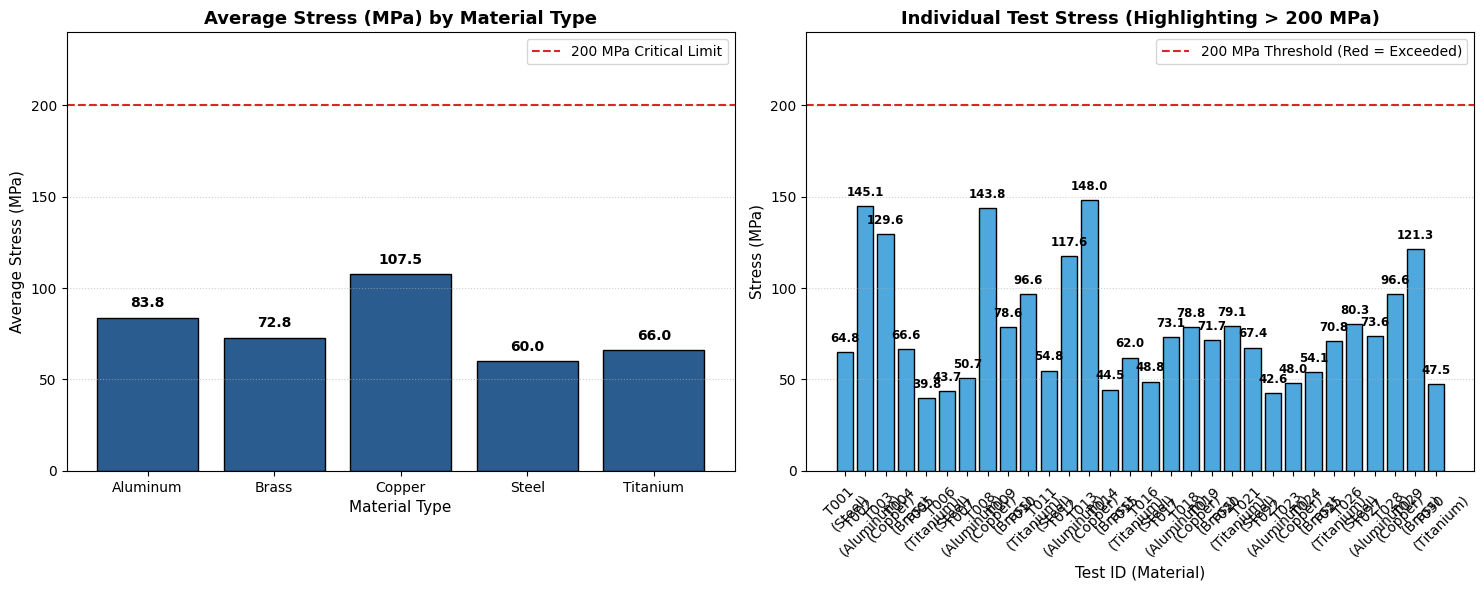

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
# Import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import files

# ---------------------------------------------------------
# Optional: Uncomment the line below to upload your file in Colab
# ---------------------------------------------------------
# uploaded = files.upload()

# 1. Load the CSV file with error handling for missing files or corrupted formats
try:
  df = pd.read_csv('stress_strain_practice.csv')
except FileNotFoundError:
  raise FileNotFoundError(
      "Error: 'stress_strain_practice.csv' was not found. Please upload it to"
      ' your Colab session.'
  )
except pd.errors.EmptyDataError:
  raise ValueError('Error: The uploaded CSV file is empty.')

# 2. Error handling for missing columns, missing values (NaN), and invalid numbers
required_cols = [
    'Test_ID',
    'Material',
    'Force_N',
    'Cross_Section_Area_mm2',
    'Elongation_mm',
    'Original_Length_mm',
]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
  raise KeyError(
      f'Error: Missing expected columns in dataset: {missing_cols}'
  )

print('--- Missing Values Audit (Before Cleaning) ---')
print(df[required_cols].isnull().sum())
print('\n')

# Safely convert numeric columns (turns text like 'N/A' or blanks into NaN)
numeric_cols = [
    'Force_N',
    'Cross_Section_Area_mm2',
    'Elongation_mm',
    'Original_Length_mm',
]
for col in numeric_cols:
  df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with missing values or zero/negative dimensions (prevents ZeroDivisionError)
initial_count = len(df)
df = df.dropna(subset=required_cols).copy()
df = df[
    (df['Cross_Section_Area_mm2'] > 0) & (df['Original_Length_mm'] > 0)
].copy()
removed_count = initial_count - len(df)

if removed_count > 0:
  print(
      f'Warning: Dropped {removed_count} row(s) due to missing values or'
      ' zero/negative dimensions.\n'
  )
else:
  print('Data Validation Passed: No missing or invalid values found.\n')

# 3. Calculate Stress (MPa) and Strain (%)
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']
df['Strain_Percent'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100

# 4. Highlight any tests where stress exceeded 200 MPa
df['Status'] = np.where(
    df['Stress_MPa'] > 200, 'EXCEEDS 200 MPa', 'Normal (<= 200 MPa)'
)
exceeded_tests = df[df['Stress_MPa'] > 200]

print('--- Highlighted Tests: Stress > 200 MPa ---')
if not exceeded_tests.empty:
  # Style DataFrame in Colab with light red background for >200 MPa rows
  try:
    display(
        exceeded_tests[[
            'Test_ID',
            'Material',
            'Force_N',
            'Cross_Section_Area_mm2',
            'Stress_MPa',
            'Status',
        ]].style.applymap(
            lambda _: 'background-color: #ffcccc; color: #900000; font-weight: bold;',
            subset=['Stress_MPa', 'Status'],
        )
    )
  except NameError:
    print(
        exceeded_tests[[
            'Test_ID',
            'Material',
            'Stress_MPa',
            'Status',
        ]].to_string(index=False)
    )
  print(
      f'Total high-stress tests (> 200 MPa): {len(exceeded_tests)} of'
      f' {len(df)}\n'
  )
else:
  print('No individual tests exceeded 200 MPa.\n')

# 5. Group by Material & Build Statistical Summary
avg_by_material = (
    df.groupby('Material')[['Stress_MPa', 'Strain_Percent']]
    .mean()
    .reset_index()
)
stress_summary = (
    df.groupby('Material')['Stress_MPa']
    .agg(
        Test_Count='count',
        Min_Stress_MPa='min',
        Max_Stress_MPa='max',
        Avg_Stress_MPa='mean',
    )
    .reset_index()
)

strongest = avg_by_material.loc[avg_by_material['Stress_MPa'].idxmax()]
print(
    f"Strongest Material: {strongest['Material']} (Avg Stress:"
    f" {strongest['Stress_MPa']:.2f} MPa)\n"
)
print('--- Material Stress Summary ---')
print(stress_summary.to_string(index=False))
print('\n')

# 6. Visualization: Bar Chart of Stress vs. Material Type (Highlighting > 200 MPa)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left Chart: Average Stress by Material Type
bar_colors_avg = [
    '#d62828' if val > 200 else '#2b5c8f'
    for val in avg_by_material['Stress_MPa']
]
bars1 = ax1.bar(
    avg_by_material['Material'],
    avg_by_material['Stress_MPa'],
    color=bar_colors_avg,
    edgecolor='black',
)
ax1.axhline(
    200,
    color='#d62828',
    linestyle='--',
    linewidth=1.5,
    label='200 MPa Critical Limit',
)

for bar in bars1:
  h = bar.get_height()
  ax1.text(
      bar.get_x() + bar.get_width() / 2,
      h + 4,
      f'{h:.1f}',
      ha='center',
      va='bottom',
      fontweight='bold',
  )

ax1.set_title(
    'Average Stress (MPa) by Material Type', fontsize=13, fontweight='bold'
)
ax1.set_xlabel('Material Type', fontsize=11)
ax1.set_ylabel('Average Stress (MPa)', fontsize=11)
ax1.set_ylim(0, max(avg_by_material['Stress_MPa'].max() * 1.2, 240))
ax1.grid(axis='y', linestyle=':', alpha=0.6)
ax1.legend()

# Right Chart: Individual Test Stress Values (Highlighting every test > 200 MPa in red)
test_labels = df['Test_ID'].astype(str) + '\n(' + df['Material'] + ')'
bar_colors_ind = [
    '#d62828' if val > 200 else '#4ea8de' for val in df['Stress_MPa']
]
bars2 = ax2.bar(
    test_labels, df['Stress_MPa'], color=bar_colors_ind, edgecolor='black'
)
ax2.axhline(
    200,
    color='#d62828',
    linestyle='--',
    linewidth=1.5,
    label='200 MPa Threshold (Red = Exceeded)',
)

for bar in bars2:
  h = bar.get_height()
  ax2.text(
      bar.get_x() + bar.get_width() / 2,
      h + 4,
      f'{h:.1f}',
      ha='center',
      va='bottom',
      fontsize=8.5,
      fontweight='bold',
  )

ax2.set_title(
    'Individual Test Stress (Highlighting > 200 MPa)',
    fontsize=13,
    fontweight='bold',
)
ax2.set_xlabel('Test ID (Material)', fontsize=11)
ax2.set_ylabel('Stress (MPa)', fontsize=11)
ax2.set_ylim(0, max(df['Stress_MPa'].max() * 1.2, 240))
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig('stress_analysis_charts.png', dpi=300)
plt.show()

# 7. Export Results and Trigger Download
df.to_csv('stress_strain_results_enhanced.csv', index=False)
stress_summary.to_csv('material_stress_summary.csv', index=False)

files.download('stress_strain_results_enhanced.csv')
files.download('material_stress_summary.csv')
files.download('stress_analysis_charts.png')